# 01 Divergence: same accuracy, different answers

Quantized Keras AkidaNet (CNN) vs the same weights converted and run on the **AKD1000** (SNN), 2000 ImageNet-C images (2 per class), fog / Gaussian noise / contrast, severities 1–5. Data: `Phase 1 - No AI/results_card/` (Yoshi's run). All intervals 95 %.

With 1000 classes and 2 images each, class-level confusion is noise, so classes are grouped into 14 WordNet groups (`aiv/imagenet_hierarchy.csv`) and distances between predictions are measured along the WordNet tree. Tests H1–H4 in `hypotheses.md`.

In [1]:
%matplotlib inline
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

In [2]:
# shared setup for all three notebooks, so not every name is used in each
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # noqa: F401

from aiv.load import CORRUPTIONS, GROUPS, NAMES, OUTCOMES, SEVERITIES, paired  # noqa: F401
from aiv.load import GROUP as GROUP_OF, table, wordnet_distance  # noqa: F401
from aiv.stats import paired_diff, wilson  # noqa: F401

RUN = "card"                      # "card" = AKD1000 run, "sim" = software simulator run
W = paired(RUN)
COND = [(c, s) for c in CORRUPTIONS for s in SEVERITIES]
COL = dict(zip(OUTCOMES, ["#d9d9d9", "#d62728", "#1f77b4", "#7f7f7f", "#ff7f0e"]))
print(f"run = {RUN} | {W.image_id.nunique()} images x {len(COND)} conditions = {len(W):,} rows | "
      f"{W.label.nunique()} classes in {len(GROUPS)} WordNet groups")

run = card | 2000 images x 15 conditions = 30,000 rows | 1000 classes in 14 WordNet groups


## Is the card the same as the simulator?
If the hardware differed from the software simulator, every later view would need two versions.

In [3]:
S = paired("sim")
m = W.merge(S, on=["image_id", "corruption", "severity"], suffixes=("", "_sim"))
print(f"Akida predictions card == sim: {(m.pred_snn == m.pred_snn_sim).mean():.4f}")
print(f"Keras predictions run card == run sim: {(m.pred_cnn == m.pred_cnn_sim).mean():.4f} "
      f"({(m.pred_cnn != m.pred_cnn_sim).sum()} of {len(m)} rows differ)")

Akida predictions card == sim: 1.0000
Keras predictions run card == run sim: 0.9969 (92 of 30000 rows differ)


## Accuracy is equal, agreement is not
Top: accuracy of both models with Wilson bands. Bottom: share of images where CNN and SNN give the *same* class, and the paired accuracy difference SNN − CNN.

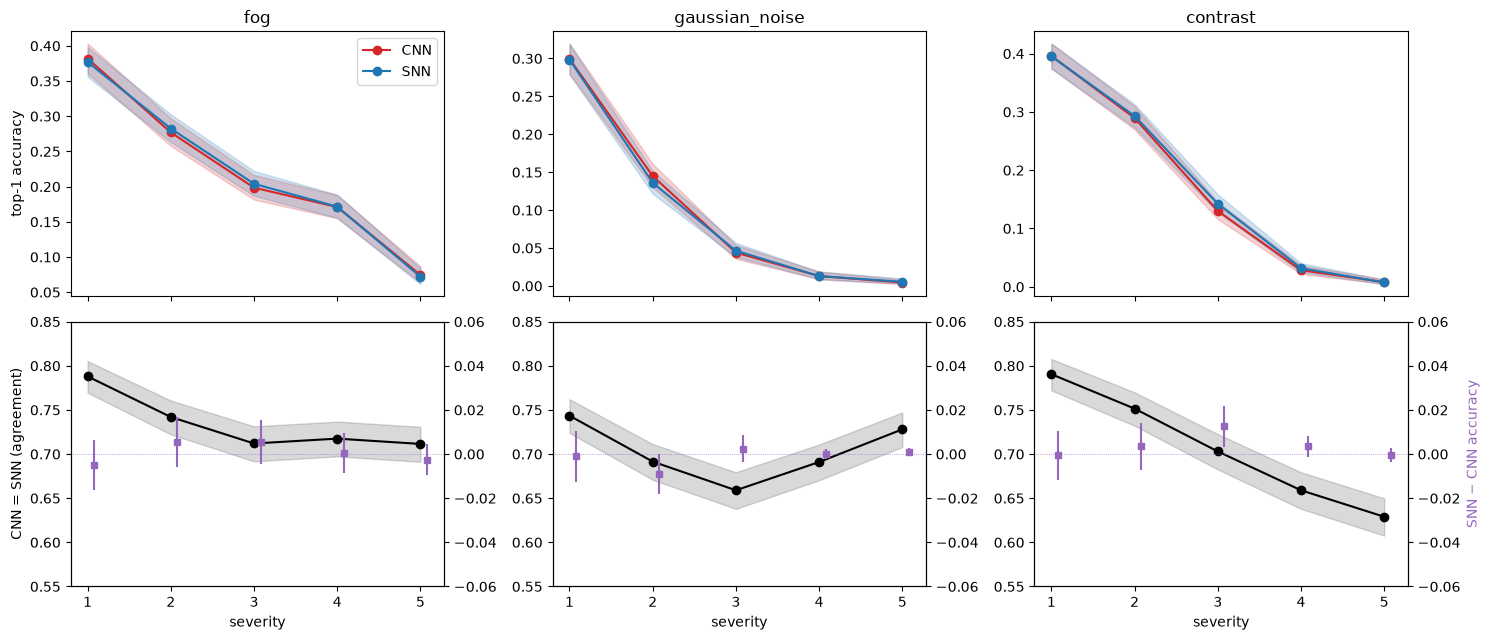

,corruption,severity,cnn,snn,gap,gap_lo,gap_hi,agree
0,fog,1,0.382,0.377,-0.005,-0.016,0.006,0.788
1,fog,2,0.277,0.282,0.006,-0.006,0.017,0.742
2,fog,3,0.198,0.204,0.006,-0.005,0.016,0.712
3,fog,4,0.171,0.172,0.000,-0.009,0.010,0.718
4,fog,5,0.074,0.072,-0.002,-0.009,0.004,0.712
5,gaussian_noise,1,0.300,0.298,-0.001,-0.013,0.011,0.744
6,gaussian_noise,2,0.145,0.136,-0.009,-0.018,0.000,0.692
7,gaussian_noise,3,0.044,0.046,0.002,-0.003,0.008,0.659
8,gaussian_noise,4,0.013,0.013,0.000,-0.002,0.002,0.691
9,gaussian_noise,5,0.004,0.006,0.001,-0.001,0.003,0.728


In [4]:
rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    lo_c, hi_c = wilson(d.cnn_ok.sum(), len(d))
    lo_s, hi_s = wilson(d.snn_ok.sum(), len(d))
    lo_a, hi_a = wilson(d.agree.sum(), len(d))
    g, glo, ghi, _ = paired_diff(d.cnn_ok, d.snn_ok)
    rows.append((c, s, d.cnn_ok.mean(), lo_c, hi_c, d.snn_ok.mean(), lo_s, hi_s,
                 d.agree.mean(), lo_a, hi_a, g, glo, ghi))
T = pd.DataFrame(rows, columns=["corruption", "severity", "cnn", "cnn_lo", "cnn_hi", "snn", "snn_lo",
                                "snn_hi", "agree", "agree_lo", "agree_hi", "gap", "gap_lo", "gap_hi"])
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for j, corr in enumerate(CORRUPTIONS):
    t = T[T.corruption == corr]
    for m, col in (("cnn", "#d62728"), ("snn", "#1f77b4")):
        axs[0, j].plot(t.severity, t[m], marker="o", color=col, label=m.upper())
        axs[0, j].fill_between(t.severity, t[f"{m}_lo"], t[f"{m}_hi"], color=col, alpha=.2)
    axs[1, j].plot(t.severity, t.agree, marker="o", color="k", label="agreement")
    axs[1, j].fill_between(t.severity, t.agree_lo, t.agree_hi, color="k", alpha=.15)
    ax2 = axs[1, j].twinx()
    ax2.errorbar(t.severity + .08, t.gap, yerr=[t.gap - t.gap_lo, t.gap_hi - t.gap], fmt="s", ms=4,
                 color="#9467bd", label="SNN − CNN accuracy")
    ax2.axhline(0, color="#9467bd", lw=.5, ls=":")
    ax2.set_ylim(-.06, .06)
    axs[0, j].set_title(corr)
    axs[1, j].set_xlabel("severity")
    axs[1, j].set_ylim(.55, .85)
    if j == 2:
        ax2.set_ylabel("SNN − CNN accuracy", color="#9467bd")
axs[0, 0].set_ylabel("top-1 accuracy")
axs[1, 0].set_ylabel("CNN = SNN (agreement)")
axs[0, 0].legend()
plt.tight_layout()
plt.show()
T.round(3)[["corruption", "severity", "cnn", "snn", "gap", "gap_lo", "gap_hi", "agree"]]

## Collapse onto sink classes
How many distinct classes each model still predicts, and which classes absorb the predictions at high severity.

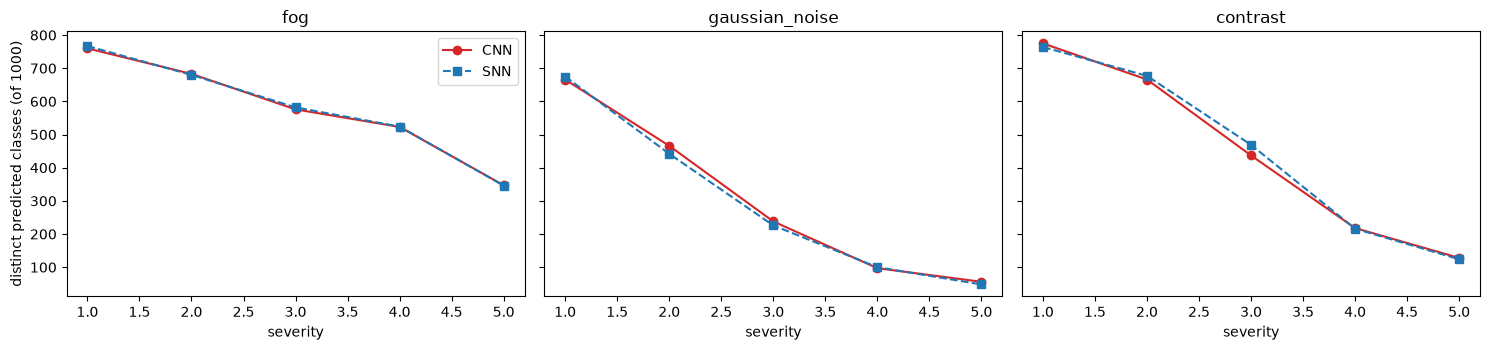

,corruption,severity,model,top-3 predicted classes
0,fog,3,CNN,mosquito net 5%; Angora 3%; axolotl 3%
1,fog,3,SNN,mosquito net 4%; Angora 3%; axolotl 3%
2,fog,5,CNN,geyser 19%; Angora 11%; dugong 4%
3,fog,5,SNN,geyser 18%; Angora 11%; dugong 4%
4,gaussian_noise,3,CNN,prayer rug 14%; mitten 9%; doormat 7%
5,gaussian_noise,3,SNN,prayer rug 14%; mitten 9%; doormat 8%
6,gaussian_noise,5,CNN,prayer rug 36%; poncho 23%; doormat 19%
7,gaussian_noise,5,SNN,prayer rug 37%; poncho 24%; doormat 18%
8,contrast,3,CNN,mosquito net 9%; nipple 2%; bassinet 2%
9,contrast,3,SNN,mosquito net 8%; nipple 2%; hoopskirt 2%


In [5]:
div = W.groupby(["corruption", "severity"], sort=False).agg(
    cnn=("pred_cnn", "nunique"), snn=("pred_snn", "nunique")).reset_index()
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, corr in zip(axs, CORRUPTIONS):
    d = div[div.corruption == corr]
    ax.plot(d.severity, d.cnn, "o-", color="#d62728", label="CNN")
    ax.plot(d.severity, d.snn, "s--", color="#1f77b4", label="SNN")
    ax.set_title(corr)
    ax.set_xlabel("severity")
axs[0].set_ylabel("distinct predicted classes (of 1000)")
axs[0].legend()
plt.tight_layout()
plt.show()

rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    if s in (3, 5):
        for m in ("cnn", "snn"):
            vc = d[f"pred_{m}"].value_counts(normalize=True).head(3)
            rows.append((c, s, m.upper(), "; ".join(f"{NAMES[k]} {v:.0%}" for k, v in vc.items())))
pd.DataFrame(rows, columns=["corruption", "severity", "model", "top-3 predicted classes"])

## Group-level confusion: CNN, SNN, and the paired difference
Rows = true WordNet group, columns = predicted group, row-normalised. Difference panels: red = the SNN sends more images there; a dot = paired 95 % interval excludes 0.

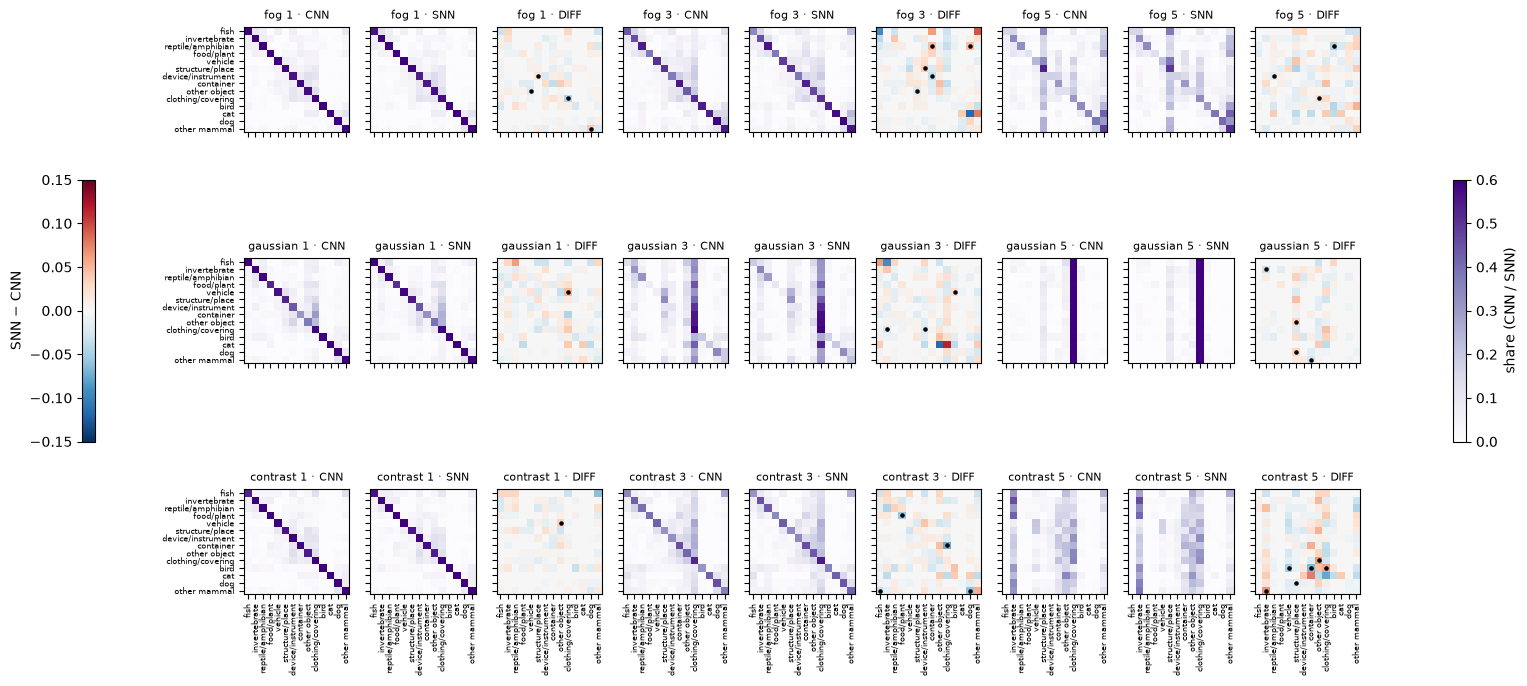

2.2% of group cells differ significantly


In [6]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

GI = {g: i for i, g in enumerate(GROUPS)}
def gmat(d, m):
    c = np.zeros((len(GROUPS), len(GROUPS)))
    np.add.at(c, (d.group.map(GI).values, d[f"group_{m}"].map(GI).values), 1)
    return c / np.maximum(c.sum(1, keepdims=True), 1)

off = (gmat(W, "cnn") + gmat(W, "snn")) / 2
np.fill_diagonal(off, 0)
sim = (off + off.T) / 2
dist = 1 - sim / sim.max()
np.fill_diagonal(dist, 0)
ORDER = leaves_list(linkage(squareform(dist, checks=False), "average"))
GN = [GROUPS[i] for i in ORDER]

rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    for t in GROUPS:
        dt = d[d.group == t]
        for p in GROUPS:
            rows.append((c, s, t, p, *paired_diff(dt.group_cnn.values == p, dt.group_snn.values == p)))
GD = pd.DataFrame(rows, columns=["corruption", "severity", "t", "p", "diff", "lo", "hi", "n"])
GD["sig"] = (GD.lo > 0) | (GD.hi < 0)

SHOW = [1, 3, 5]
fig, axs = plt.subplots(3, 9, figsize=(24, 8.5), sharex=True, sharey=True)
for i, corr in enumerate(CORRUPTIONS):
    for j, s in enumerate(SHOW):
        d = W[(W.corruption == corr) & (W.severity == s)]
        for k, kind in enumerate(("cnn", "snn", "diff")):
            ax = axs[i, j * 3 + k]
            if kind == "diff":
                M = (gmat(d, "snn") - gmat(d, "cnn"))[np.ix_(ORDER, ORDER)]
                im_d = ax.imshow(M, cmap="RdBu_r", vmin=-.15, vmax=.15)
                sg = GD[(GD.corruption == corr) & (GD.severity == s) & GD.sig]
                ax.scatter([GN.index(p) for p in sg.p], [GN.index(t) for t in sg.t], s=5, c="k")
            else:
                im = ax.imshow(gmat(d, kind)[np.ix_(ORDER, ORDER)], cmap="Purples", vmin=0, vmax=.6)
            ax.set_title(f"{corr[:8]} {s} · {kind.upper()}", fontsize=8)
for ax in axs[-1]:
    ax.set_xticks(range(len(GN)))
    ax.set_xticklabels(GN, rotation=90, fontsize=6)
for ax in axs[:, 0]:
    ax.set_yticks(range(len(GN)))
    ax.set_yticklabels(GN, fontsize=6)
fig.colorbar(im, ax=axs, shrink=.4, location="right", label="share (CNN / SNN)")
fig.colorbar(im_d, ax=axs, shrink=.4, location="left", label="SNN − CNN")
plt.show()
print(f"{GD.sig.mean():.1%} of group cells differ significantly")

## When they disagree, how far apart are the two answers?
WordNet distance (edges via the lowest common ancestor) between the CNN's and the SNN's class, only where they differ. Grey band: the same distance for random class pairs (5000 draws, 25–75 %).

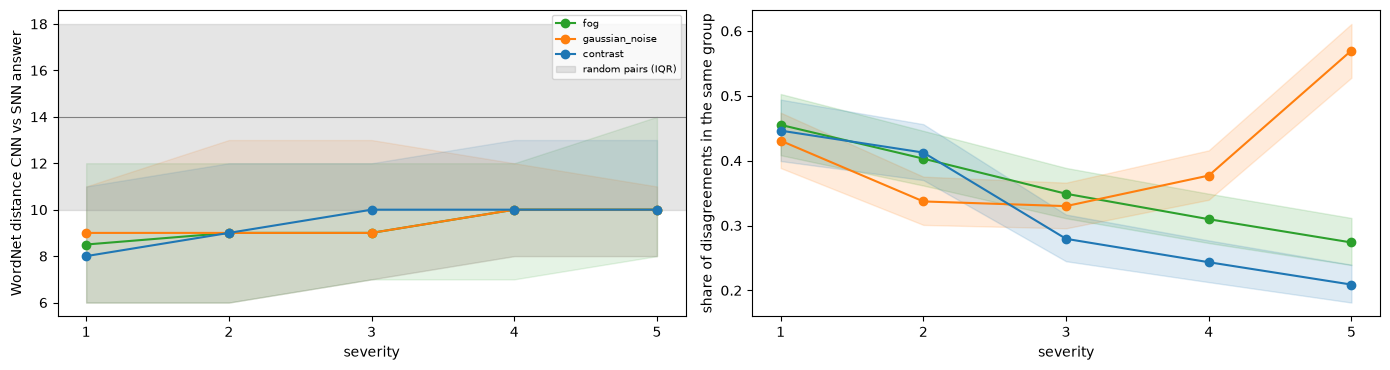

random pairs: median distance 14, same group 0.10


In [7]:
rng = np.random.default_rng(0)
a, b = rng.integers(0, 1000, 5000), rng.integers(0, 1000, 5000)
RND = np.array([wordnet_distance(x, y) for x, y in zip(a, b) if x != y])
D = W[~W.agree].copy()
D["dist"] = [wordnet_distance(x, y) for x, y in zip(D.pred_cnn, D.pred_snn)]
D["same_group"] = D.group_cnn == D.group_snn
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
for corr, col in zip(CORRUPTIONS, ["#2ca02c", "#ff7f0e", "#1f77b4"]):
    g = D[D.corruption == corr].groupby("severity")
    q = g.dist.quantile([.25, .5, .75]).unstack()
    axs[0].plot(q.index, q[.5], "o-", color=col, label=corr)
    axs[0].fill_between(q.index, q[.25], q[.75], color=col, alpha=.12)
    k, n = g.same_group.sum(), g.size()
    lo, hi = wilson(k, n)
    axs[1].plot(k.index, k / n, "o-", color=col, label=corr)
    axs[1].fill_between(k.index, lo, hi, color=col, alpha=.15)
axs[0].axhspan(*np.percentile(RND, [25, 75]), color="grey", alpha=.2, label="random pairs (IQR)")
axs[0].axhline(np.median(RND), color="grey", lw=.8)
axs[0].set_ylabel("WordNet distance CNN vs SNN answer")
axs[0].legend(fontsize=7)
axs[1].set_ylabel("share of disagreements in the same group")
for ax in axs:
    ax.set_xlabel("severity")
    ax.set_xticks(SEVERITIES)
plt.tight_layout()
plt.show()
gr = np.array(GROUP_OF)
print(f"random pairs: median distance {np.median(RND):.0f}, same group "
      f"{np.mean(gr[a] == gr[b]):.2f}")

## Drill-down
Pick any cell above; with the image subset on disk this shows the images.

In [8]:
from pathlib import Path

# Thumbnails need the image subset from scripts/make_imagenet_subset.py (not in the repo).
IMAGENET_C_DIR = Path("../../data/imagenet_subset/imagenet-c")

def show(df, n=16, cols=8, title=""):
    """Images behind a selection; falls back to a table if the subset is not on this machine."""
    df = df.head(n).assign(cnn=lambda d: NAMES[d.pred_cnn], snn=lambda d: NAMES[d.pred_snn])
    if not IMAGENET_C_DIR.exists():
        print(f"{title}  (no {IMAGENET_C_DIR}: table only)")
        return df[["image_id", "corruption", "severity", "true", "cnn", "snn"]]
    import matplotlib.image as mpimg
    rows = int(np.ceil(len(df) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 2), squeeze=False)
    for ax in axs.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axs.flat, df.iterrows()):
        ax.imshow(mpimg.imread(IMAGENET_C_DIR / r.corruption / str(r.severity) / r.image_id))
        ax.set_title(f"{r.true[:12]}\nC:{r.cnn[:12]}\nS:{r.snn[:12]}", fontsize=6)
    fig.suptitle(title, fontsize=9)
    plt.tight_layout()
    plt.show()

In [9]:
sel = W[(W.corruption == "contrast") & (W.severity == 3) & (W.outcome == "only SNN right")]
print(len(sel), "images where only the SNN is right at contrast 3")
show(sel, title="only SNN right, contrast 3")

56 images where only the SNN is right at contrast 3
only SNN right, contrast 3  (no ../../data/imagenet_subset/imagenet-c: table only)


,image_id,corruption,severity,true,cnn,snn
24017,n01514859/ILSVRC2012_val_00001368.JPEG,contrast,3,hen,hornbill,hen
24033,n01560419/ILSVRC2012_val_00000217.JPEG,contrast,3,bulbul,African chameleon,bulbul
24054,n01631663/ILSVRC2012_val_00000258.JPEG,contrast,3,eft,scorpion,eft
24059,n01632777/ILSVRC2012_val_00001138.JPEG,contrast,3,axolotl,hammerhead,axolotl
24066,n01664065/ILSVRC2012_val_00000404.JPEG,contrast,3,loggerhead,terrapin,loggerhead
24077,n01675722/ILSVRC2012_val_00004638.JPEG,contrast,3,banded gecko,plastic bag,banded gecko
24083,n01685808/ILSVRC2012_val_00004757.JPEG,contrast,3,whiptail,horned viper,whiptail
24128,n01749939/ILSVRC2012_val_00000298.JPEG,contrast,3,green mamba,lacewing,green mamba
24129,n01749939/ILSVRC2012_val_00001185.JPEG,contrast,3,green mamba,lacewing,green mamba
24160,n01795545/ILSVRC2012_val_00000075.JPEG,contrast,3,black grouse,electric ray,black grouse


## Findings (01 divergence)

Run: Yoshi's `results_card/` (AKD1000), 2000 ImageNet-C images, 15 conditions. 95 % intervals.

1. **The card is the simulator.** The Akida predictions on the AKD1000 and in the software
   simulator are identical on all 30 000 rows. The quantized Keras baseline is *not* fully
   reproducible: its two runs differ on 92 rows (0.3 %). Use one Keras run for all comparisons.
2. **Same accuracy, different answers.** The paired accuracy gap SNN − CNN is within ±1 pp
   everywhere. The only interval that excludes 0 is contrast 3: +1.2 pp [+0.3, +2.2], 56
   images only the SNN gets right vs 31 only the CNN gets right (binomial p = 0.01). Yet the two
   models give a *different* class for 21–26 % of images at severity 1, and for up to 37 % at
   contrast 5. The divergence lives almost entirely in *which wrong class* is chosen.
3. **Both collapse onto the same sinks.** The number of distinct predicted classes falls from
   ~770 (severity 1) to 56 / 48 (CNN / SNN, noise 5). At noise 5, prayer rug (36–37 %), poncho
   (23–24 %) and doormat (18–19 %) take most predictions. At fog 5 it is geyser (18–19 %), at
   contrast 5 nematode (16–18 %). The top class is the same for both models in 13 of 15
   conditions. This explains the U-shape in agreement under noise (0.74 → 0.66 at sev 3 → 0.73 at
   sev 5): at noise 5, 84 % of images where both agree *and* are wrong land in one of the three
   sink classes.
4. **Disagreements are near misses.** When CNN and SNN differ, their two answers are 8–10
   WordNet edges apart (median), against 14 for random class pairs. At severity 1, 43–46 % of
   disagreements stay in the same group (chance: 10 %). As severity grows, fog and contrast
   disagreements spread out (same group 0.27 / 0.21 at sev 5), while noise disagreements
   *converge* (0.57 at sev 5) because both are pulled to the clothing/covering sinks.
5. **No group-level divergence.** Only 2.2 % of the group-confusion cells differ significantly
   between the two models, below the 5 % expected by chance alone. At group level, CNN and SNN make
   the same kind of mistakes. The divergence is class-level and near-tie, not systematic.
6. **Drill-down (contrast 3, only SNN right, 56 images):** mostly animals the CNN confuses
   with another animal or object (green mamba → lacewing, axolotl → hammerhead, chow →
   Pomeranian). The images themselves are not in the repo; with `data/imagenet_subset/` the
   cell shows them.

Limits: no clean condition (severity 1 is the reference), 2 images per class, no confidence
scores, one Keras run.
